## Cosmic Web - Synthesis

In this notebook we read the stage files and draw the comparison: the curves, one call per tool on a shared timeline, each tool's time against its bytes roof, and the curve of the simulation cube.

### Table of Contents

1. [Stage files](#1-stage-files)
2. [One call per tool](#2-one-call-per-tool)
3. [Bytes roof](#3-bytes-roof)
4. [The simulation cube](#4-the-simulation-cube)
5. [Four programming models](#5-four-programming-models)

---

### 1. Stage files

Each notebook left one file per stage under `timings/`: its histogram, timing, launch count and trace. The four compared are the CuPy reference, JAX, cuda.compute and the CppJIT kernel. The three TODO variants (CuPy views, JAX slabs, CppJIT CUB) appear beside them.

In [1]:
import numpy as np
import cupy as cp

import cosmic_core as cw

STAGES = ['cupy', 'jax', 'cccl', 'cppjit_cuda']
EXTRAS = ['cupy_views', 'jax_private', 'cppjit_cub']
LABELS = {'cupy': 'CuPy', 'cupy_views': 'CuPy views', 'jax': 'JAX', 'jax_private': 'JAX slabs',
          'cccl': 'cuda.compute', 'cppjit_cub': 'CppJIT CUB', 'cppjit_cuda': 'CppJIT CUDA'}

by_stage = cw.load_stages(STAGES, EXTRAS)
N, K = by_stage['cupy']['n'], by_stage['cupy']['k']
cw.stage_table(by_stage, LABELS)

stage files recorded on NVIDIA GeForce RTX 4080 SUPER

tool             N    K   warm ms   cold ms  max|Δχ|   Σ
CuPy          512^3  128     53.40      59.3        0   0
JAX           512^3  128    141.59     248.1        0   0
cuda.compute  512^3  128     13.72   12793.4        0   0
CppJIT CUDA   512^3  128      1.56      32.0        0   0
CuPy views    512^3  128     36.47      36.6        0   0
JAX slabs     512^3  128     16.31     134.6        0   0
CppJIT CUB    512^3  128     36.07    1843.9        0   0


### 2. One call per tool

Three figures from the stage files: the curves against the reference, one call per tool on a shared time axis, and one call's wall time split into kernels, copies and the host's remainder. Does any tool leave the GPU idle while the host works?

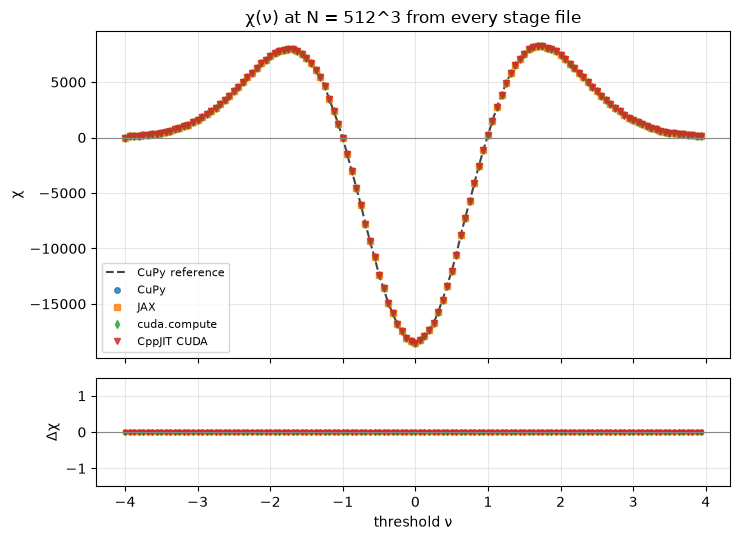

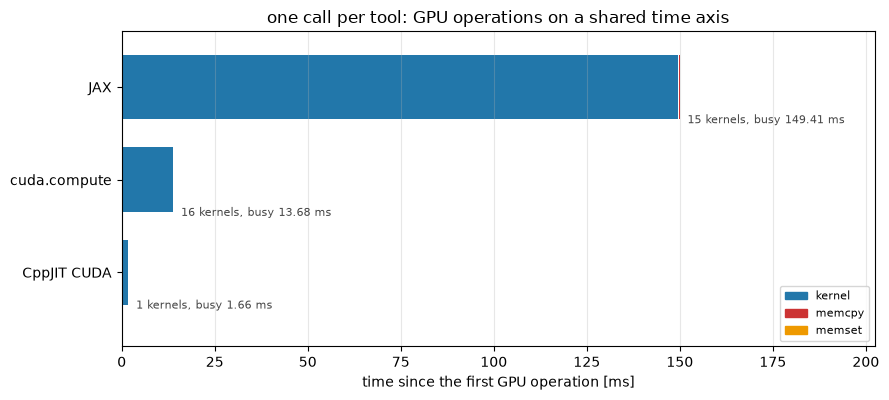

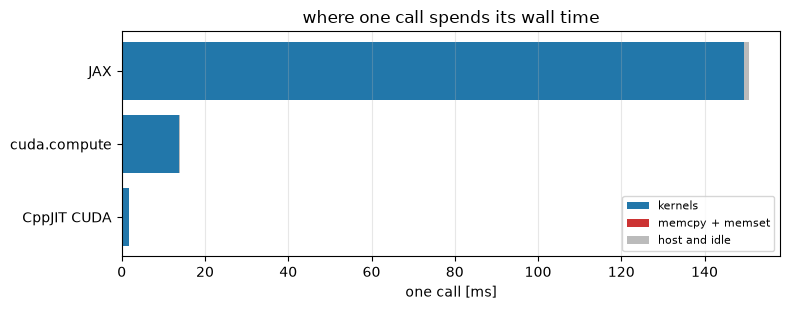

In [2]:
edges = cw.bin_edges(K)
reference = cw.chi_reference(N)
curves = {LABELS[s]: cw.ecc_from_hist(by_stage[s]['hist']) for s in STAGES if s in by_stage and 'hist' in by_stage[s]}
cw.plot_curves_with_delta(edges, curves, reference, title=f'χ(ν) at N = {N}^3 from every stage file')

traced = [s for s in STAGES if s in by_stage and 'trace' in by_stage[s] and 'launches' in by_stage[s]]
cw.plot_timelines({LABELS[s]: by_stage[s]['trace'] for s in traced},
                  title='one call per tool: GPU operations on a shared time axis')

parts = {LABELS[s]: cw.wall_breakdown(by_stage[s]) for s in traced}
cw.plot_breakdown(parts, title='where one call spends its wall time')

- On the timeline, JAX's few long kernels outlast CuPy's many short ones: at this size the kernel durations set the time.
- The host share is small in every bar: host work leaves the GPU idle for little of the call.

### 3. Bytes roof

We plot the time per call against size for every tool, with its bytes model dashed at the measured copy bandwidth, then each tool's first call against its warm median. Which tools reach their roofs?

      N          CuPy           JAX  cuda.compute   CppJIT CUDA    CuPy views     JAX slabs   Gvoxel/s
  64^3          0.290         0.621         0.735        11.413         0.329         1.330
 128^3          2.218         0.833         5.297        49.543         2.527         5.917
 256^3          2.415         0.867        10.771        78.198         3.553         8.256
 512^3          2.513         0.947         9.721        83.560         3.677         8.452


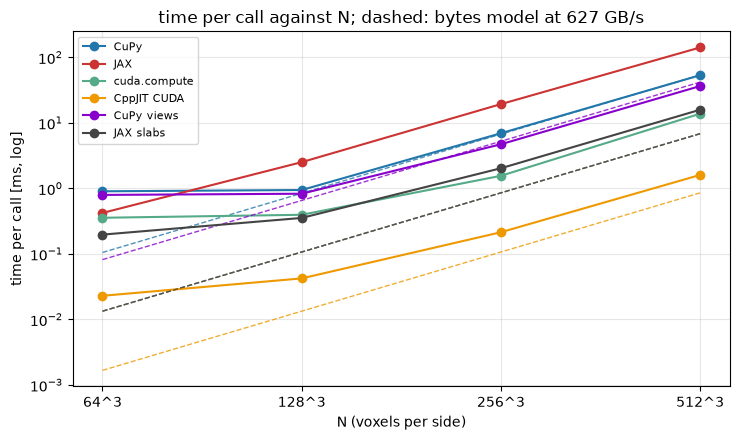

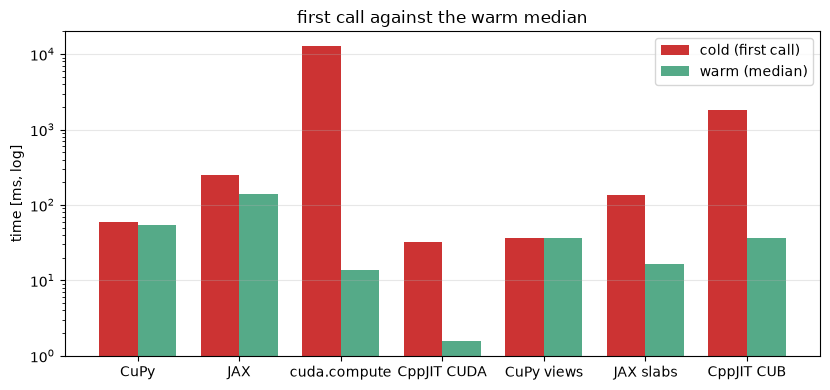

In [3]:
gbs = cw.copy_roof_gbs()
swept = [s for s in by_stage if 'sweep' in by_stage[s]]
cw.sweep_series(by_stage, {s: LABELS[s] for s in swept})
cw.plot_bytes_roof({LABELS[s]: by_stage[s]['sweep'] for s in swept}, {LABELS[s]: s for s in swept}, gbs,
                   title=f'time per call against N; dashed: bytes model at {gbs:.0f} GB/s')

cold = [s for s in by_stage if 'cold_s' in by_stage[s]]
cw.plot_cold_warm([LABELS[s] for s in cold], [by_stage[s]['cold_s'] for s in cold],
                  [by_stage[s]['median_s'] for s in cold], 'first call against the warm median')

- At the smallest size every tool is far from its roof: the launch count sets the time.
- As the size grows every line runs parallel to its roof.
- CuPy reaches its roof. The kernel, the library passes and JAX stay above theirs.

### 4. The simulation cube

We draw the curve of the cube, or of its Zel'dovich stand-in, against the Gaussian expectation, with the formula's parameter $\lambda$ taken from the cube.

no real density cube found (data/df_m_256_CIC_z=0.npy or $COSMIC_WEB_DATA): using the Zel'dovich stand-in
  the Quijote fiducial 256^3 CIC cube at z = 0 (Villaescusa-Navarro et al. 2020, ApJS 250, 2, doi:10.3847/1538-4365/ab9d82) is distributed through Globus;
  place it under data/ or point COSMIC_WEB_DATA at its directory to use it here


Zel'dovich stand-in: N = 512^3, box 1000 Mpc/h, sigma8 0.834, seed 2026, R = 3 voxels


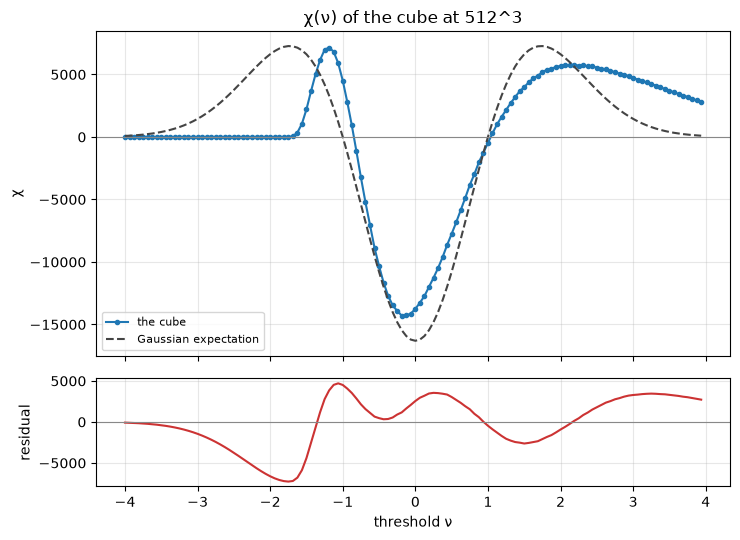

zero crossings: the cube [-0.85, 1.04], the Gaussian expectation [-1.0, 1.0]


In [4]:
nu, lam, _ = cw.load_dataset()
q = cw.quantise(cp.asarray(nu), K)
hist = cp.asnumpy(cw.ecc_hist_cupy(q, K))
assert hist.sum() == 0, hist.sum()
chi = cw.ecc_from_hist(hist)
pred = cw.chi_gaussian(edges, lam, q.size)
_, zeros = cw.plot_overlay(edges, chi, pred, title=f'χ(ν) of the cube at {q.shape[0]}^3', label='the cube')
print(f'zero crossings: the cube {np.round(zeros, 2).tolist()}, '
      f'the Gaussian expectation {np.round(cw.zero_crossings(edges, pred), 2).tolist()}')

- The printed crossings show where the cube's curve departs from the expectation's $\pm 1$.

### 5. Four programming models

| model | it decides for us | it leaves to us | where it stops |
|---|---|---|---|
| **Array model** (CuPy) | one kernel per expression, every temporary | the expressions, the dtype, views and buffers | no fusion across lines |
| **Traced graph** (JAX) | the fusion, the executable, its memory plan | the function and its static arguments | a scatter is a boundary |
| **Algorithm over iterators** (cuda.compute) | the kernel of each algorithm, the fusion of the iterators into it | the algorithm and the iterators | one output per call; an op reads no array |
| **Kernel and interoperability** (CppJIT CUDA) | the binding and the launcher | the thread mapping, the shared memory, the launch, the stream | the first use pays the compile; a name is defined once per session |

Takeaways:

- The same algorithm had four cost structures: CuPy's temporaries, JAX's scatters, cuda.compute's eight library passes, one kernel of our own.
- The integer gate made the four timings comparable: every tool produced the same histogram, bin for bin.